In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget
%pwd

'/projectnb/batmanlab/mragoza/lung-project/notebooks/bmc-4dct'

In [2]:
import sys, os

def add_path(p: str):
    if p not in sys.path:
        sys.path.append(p)

add_path(os.environ['LP_ROOT'])
import project

add_path(os.environ['PROJECT'] + '/' + 'param_search')
import param_search as ps

ps.set_backend('sge')
ps.set_verbose(False)

# Gather examples

In [3]:
from pathlib import Path
data_root = Path(os.environ['PRIVATE']) / 'data' / 'BMC-4DCT'
data_root.exists()

True

In [4]:
manifest_path = data_root / 'metadata' / 'phase_manifest.csv'
manifest = project.fileio.load_csv(manifest_path)
manifest.head()

Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/metadata/phase_manifest.csv


,case_id,subject_num,study_num,scan_role,resp_phase,image_path,series_description,case_phases,case_valid
0,4DCT_10_1,10,1,4DCT,0.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,0 0% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
1,4DCT_10_1,10,1,4DCT,10.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,10 10% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
2,4DCT_10_1,10,1,4DCT,20.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,20 20% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
3,4DCT_10_1,10,1,4DCT,30.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,30 30% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True
4,4DCT_10_1,10,1,4DCT,40.0,converted/2026-03-25_batch/4DCT/4D0010_1/4D001...,40 40% Linear,"(0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0...",True


In [5]:
case_data = manifest[manifest.case_valid].sort_values(by=['subject_num', 'study_num'])
case_list = case_data.case_id.unique().tolist()
print(case_list)

['4DCT_1_1', '4DCT_2_1', '4DCT_2_2', '4DCT_4_1', '4DCT_6_1', '4DCT_7_3', '4DCT_8_1', '4DCT_8_2', '4DCT_10_1', 'unknown_12_1', 'unknown_13_1', 'unknown_14_1', 'unknown_15_1', 'unknown_16_1', 'unknown_17_1', 'unknown_17_3', 'unknown_18_1', 'unknown_19_1', 'unknown_20_1', 'unknown_22_1', 'unknown_23_1', 'unknown_26_1', 'unknown_27_1', 'unknown_28_1', 'unknown_29_1', 'unknown_30_1', 'unknown_31_1', 'unknown_32_1', 'unknown_33_1', 'unknown_34_1', 'unknown_36_1', 'unknown_37_1', 'unknown_38_1', 'unknown_39_1', 'unknown_40_1', 'unknown_40_5', 'unknown_42_1', 'unknown_42_4', 'unknown_43_1', 'unknown_44_1', 'unknown_45_1', 'unknown_47_1', 'unknown_49_1', 'unknown_50_1', 'unknown_51_1', 'unknown_52_1', 'unknown_53_1']


In [6]:
config = project.fileio.load_config('2026-11-01_config.yaml')

config['dataset']['variant'] = '2026-11-01'
config['dataset']['subjects'] = case_list
config['dataset']['state_pairs'] = [(50, 0)]
config['dataset']['pipeline_tags']['image_registration'] = 'gil'
config['dataset']['pipeline_tags']['material_properties'] = 'const'
config['dataset']['pipeline_tags']['field_interpolation'] = 'int'

config['training']['split']['method'] = 'metadata'
config['training']['split']['key'] = 'subject_num'
config['training']['split']['test_ratio'] = 0.2
config['training']['split']['val_ratio'] = 0.2
config['training']['split']['seed'] = 11

examples = project.get_examples(config['dataset'])

Loading 2026-11-01_config.yaml
Gathering examples...
47 total


# Setup experiment

In [30]:
base_dir = '2026-11-11_train' 

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=32G
#$ -l h_rt=24:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH
export PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"

python $LP_ROOT/scripts/train.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects={subjects} \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set training.split.method=metadata \\
    --set training.split.key=subject_num \\
    --set training.split.test_ratio=0.2 \\
    --set training.split.val_ratio=0.2 \\
    --set training.split.seed=11 \\
    --set training.model.backbone.out_channels=8 \\
    --set training.optimizer.lr=1e-4 \\
    --set training.pde_solver.material_type={material_type} \\
    --set training.pde_solver.tv_reg_weight={tv_reg_weight} \\
    --set training.pde_solver.cg_maxiter=10000 \\
    --set training.pde_solver.newton_atol=5e-5 \\
    --set training.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subjects=','.join(case_list),
    curr_phase=[0,10,20,30,40,60,70,80,90],
    reg_tag='gil',
    mat_tag='const',
    material_type=['LE', 'NH'],
    tv_reg_weight=[1e-4],
    conv_channels=8,
    learning_rate=1e-4,
    random_seed=range(3)
)

len(grid)

54

In [31]:
base_dir = '2026-11-13_train' 

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=32G
#$ -l h_rt=24:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH
export PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"

python $LP_ROOT/scripts/train.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects={subjects} \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set training.split.method=metadata \\
    --set training.split.key=subject_num \\
    --set training.split.test_ratio=0.2 \\
    --set training.split.val_ratio=0.2 \\
    --set training.split.seed=11 \\
    --set training.model.backbone.out_channels=8 \\
    --set training.model.heads.E.v_max={E_max} \\
    --set training.model.heads.E.beta={E_beta} \\
    --set training.optimizer.lr=1e-4 \\
    --set training.pde_solver.material_type={material_type} \\
    --set training.pde_solver.tv_reg_weight=1e-4 \\
    --set training.pde_solver.cg_maxiter=10000 \\
    --set training.pde_solver.newton_atol=5e-5 \\
    --set training.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subjects=','.join(case_list),
    curr_phase=[0],
    reg_tag='gil',
    mat_tag='const',
    E_max=[1e5, 2e4],
    E_beta=[None, 1.0],
    material_type=['LE', 'NH'],
    random_seed=range(3)
)

len(grid)

24

In [17]:
base_dir = '2026-11-15_train' 

# changelist:
# - set eps_err=1e-12 (prev: 1e-6)
# - clip gradient magnitude to 1.0

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=32G
#$ -l h_rt=24:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH
export PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"

python $LP_ROOT/scripts/train.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects={subjects} \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set training.split.method=metadata \\
    --set training.split.key=subject_num \\
    --set training.split.test_ratio=0.2 \\
    --set training.split.val_ratio=0.2 \\
    --set training.split.seed=11 \\
    --set training.model.backbone.out_channels=8 \\
    --set training.model.heads.E.v_max={E_max} \\
    --set training.model.heads.E.beta={E_beta} \\
    --set training.optimizer.lr=1e-4 \\
    --set training.pde_solver.material_type={material_type} \\
    --set training.pde_solver.tv_reg_weight=1e-4 \\
    --set training.pde_solver.eps_err=1e-12 \\
    --set training.pde_solver.cg_maxiter=10000 \\
    --set training.pde_solver.newton_atol=5e-5 \\
    --set training.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subjects=','.join(case_list),
    curr_phase=[0,10,20,30,40,60,70,80,90],
    reg_tag='gil',
    mat_tag='const',
    E_max=[1e5],
    E_beta=[None],
    material_type=['LE', 'NH'],
    random_seed=range(3)
)

len(grid)

54

In [19]:
base_dir = '2026-11-16_train' 

# changelist:
# - sweep TV reg weight

template = '''\
#!/bin/bash -l
#$ -N {job_name}
#$ -P batmanlab
#$ -pe omp 4
#$ -l gpus=1
#$ -l gpu_memory=32G
#$ -l h_rt=24:00:00
set -eo pipefail

mamba activate $PROJECT/mambaforge/envs/warp

export PYTHONPATH=$LP_ROOT:$PROJECT:$PYTHONPATH
export PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True"

python $LP_ROOT/scripts/train.py {config} \\
    --set dataset.variant={variant} \\
    --set dataset.subjects={subjects} \\
    --set dataset.state_pairs="[[50, {curr_phase}]]" \\
    --set dataset.pipeline_tags.image_registration={reg_tag} \\
    --set dataset.pipeline_tags.material_properties={mat_tag} \\
    --set dataset.pipeline_tags.field_interpolation=int \\
    --set training.split.method=metadata \\
    --set training.split.key=subject_num \\
    --set training.split.test_ratio=0.2 \\
    --set training.split.val_ratio=0.2 \\
    --set training.split.seed=11 \\
    --set training.model.backbone.out_channels=8 \\
    --set training.model.heads.E.v_max={E_max} \\
    --set training.model.heads.E.beta={E_beta} \\
    --set training.optimizer.lr=1e-4 \\
    --set training.pde_solver.material_type={material_type} \\
    --set training.pde_solver.tv_reg_weight={tv_reg_weight} \\
    --set training.pde_solver.eps_err=1e-12 \\
    --set training.pde_solver.cg_maxiter=10000 \\
    --set training.pde_solver.newton_atol=5e-5 \\
    --set training.seed={random_seed}

'''
name_format = 'job_{params_hash}'

grid = ps.param_grid(
    config='2026-11-01_config.yaml',
    variant='2026-11-01',
    subjects=','.join(case_list),
    curr_phase=[0],
    reg_tag='gil',
    mat_tag='const',
    E_max=[1e5],
    E_beta=[None],
    material_type=['LE'],
    tv_reg_weight=[1e-4, 1e-3, 1e-2],
    random_seed=range(3)
)

len(grid)

9

In [20]:
jobs = ps.setup(base_dir, template, name_format, grid, overwrite=True)
jobs

,job_name,job_state,n_submits,job_id,node_id,runtime,stdout,stderr,base_dir,work_dir,...,params.variant,params.subjects,params.curr_phase,params.reg_tag,params.mat_tag,params.E_max,params.E_beta,params.material_type,params.tv_reg_weight,params.random_seed
0,job_6f122f283a512928,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0001,0
1,job_cefe4c5f6fa4011c,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0001,1
2,job_19d7ed56ccb43e2e,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0001,2
3,job_be26138dea45ad53,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0010,0
4,job_dea52f3bd5c3cb90,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0010,1
5,job_abf740f3ac8c2c46,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0010,2
6,job_7645f1b595ddeaf6,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0100,0
7,job_4daccebcae73c441,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0100,1
8,job_157ebe336f58c362,NEW,0,<NA>,<NA>,<NA>,<NA>,<NA>,/projectnb/batmanlab/mragoza/lung-project/note...,/projectnb/batmanlab/mragoza/lung-project/note...,...,2026-11-01,"4DCT_1_1,4DCT_2_1,4DCT_2_2,4DCT_4_1,4DCT_6_1,4...",0,gil,const,100000.0,None,LE,0.0100,2


In [21]:
jobs = ps.submit(jobs)

# Monitor submitted jobs

In [22]:
jobs = ps.load('2026-11-16_train')

In [23]:
jobs = ps.recover(jobs)
jobs = ps.status(jobs)
jobs = ps.history(jobs)
jobs = ps.collect(jobs)
jobs.groupby('job_state').size()

job_state
RUNNING    9
dtype: int64

In [24]:
import pandas as pd

def classify_output(stdout: str):
    if pd.isnull(stdout):
        return 'No stdout file'
    elif not str(stdout).strip():
        return 'No output message'
    elif 'Done' in stdout:
        return 'Complete'
    return 'Incomplete'

def classify_error(stderr: str):
    if pd.isnull(stderr):
        return 'No stderr file'    
    elif not str(stderr).strip():
        return 'No error message'
    elif 'Segmentation fault' in stderr:
        return 'Segmentation fault'
    elif 'CUDA out of memory' in stderr or 'Failed to allocate' in stderr:
        return 'CUDA out of memory'
    elif 'No CUDA GPUs are available' in stderr:
        return 'CUDA not available'
    elif 'Warp UserWarning' in stderr:
        return 'Warp user warning'
    elif 'Newton solver failed to converge' in stderr:
        return 'Failed to converge'
    elif 'Non-finite PDE residual' in stderr:
        return 'Non-finite PDE residual'
    elif 'WARNING: No metrics found' in stderr:
        return 'Load metrics warning'
    elif 'WARNING: No checkpoints found' in stderr:
        return 'Load checkpoint warning'
    return 'Uncategorized'

jobs['error_type'] = jobs.stderr.map(classify_error)
jobs['output_type'] = jobs.stdout.map(classify_output)

jobs.groupby(['params.material_type', 'params.E_max', 'output_type', 'error_type'], dropna=False)[['job_name']].count()

,,,,job_name
params.material_type,params.E_max,output_type,error_type,
LE,100000.0,Incomplete,Load checkpoint warning,9


In [22]:
query = jobs.error_type.eq('Uncategorized')
query_jobs = jobs[query]

job = query_jobs.iloc[0]
print(job)
print(job.stdout)
print(job.stderr)

AttributeError: 'DataFrame' object has no attribute 'error_type'

# Analyze outputs

In [23]:
jobs = ps.load('2026-11-15_train').set_index(
    ['params.curr_phase', 'params.material_type', 'params.random_seed'],
    verify_integrity=True
)

In [24]:
metrics = ps.outputs(
    jobs.reset_index(),
    meta_cols=['base_dir', 'job_name', 'job_id'],
    output_name='outputs/training/default/eval_metrics.csv',
    skip_errors=True
)

100%|██████████| 54/54 [00:01<00:00, 30.67it/s]


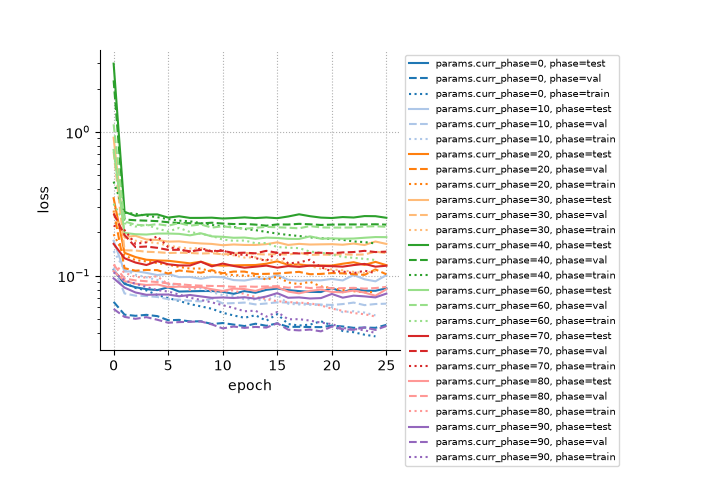

In [33]:
import project.visual.matplotlib as mpl_viz
import matplotlib.pyplot as plt

def training_plot(data, x, y, hue, style, agg='mean'):
    fig, axes = mpl_viz.subplot_grid(1, 1, 3, 3, padding=(1.0,3.25,1.5,0.5))
    colors = plt.get_cmap('tab20')
    styles = ['-', '--', ':']
    groupby_kws = dict(dropna=False, sort=False)
    for i, (hue_key, hue_data) in enumerate(data.groupby(hue, **groupby_kws)):
        for j, (style_key, style_data) in enumerate(hue_data.groupby(style, **groupby_kws)):
            points = style_data[[x, y]].dropna()
            if agg:
                points = points.groupby(x, as_index=False, sort=True)[y].agg(agg)
            else:
                points = points.sort_values(x)
            if points.empty:
                continue
            key_vals = dict(zip(hue, hue_key))
            key_vals[style] = style_key
            label = ', '.join(f'{k}={v}' for k, v in key_vals.items())
            axes[0,0].plot(
                points[x],
                points[y],
                color=colors(i % colors.N),
                linestyle=styles[j % len(styles)],
                label=label
            )
            axes[0,0].set_xlabel(x)
            axes[0,0].set_ylabel(y)
            axes[0,0].set_yscale('log')
            axes[0,0].grid(linestyle=':')
            axes[0,0].spines[['top', 'right']].set_visible(False)

    handles, labels = axes[0,0].get_legend_handles_labels()
    axes[0,0].legend(handles, labels, bbox_to_anchor=(1.0,1.0), loc='upper left', fontsize='x-small')
    return fig, axes

metrics['mat'] = metrics['params.material_type']
#metrics['E_max'] = metrics['params.E_max']

fig, axes = training_plot(
    metrics[metrics['params.material_type'].eq('LE')],
    x='epoch',
    y='loss',
    hue=['params.curr_phase'],
    style='phase'
)
plt.pause(1.0)

In [31]:
fig.savefig('2026-11-15_train_plot.png', bbox_inches='tight')
fig.savefig('2026-11-15_train_plot.pdf', bbox_inches='tight')

In [77]:
# evaluate magnitude of observed deformations

from pathlib import Path
import torch

def get_config(case_id, curr_phase, material_type):
    config = project.fileio.load_config('../bmc-4dct/2026-11-01_config.yaml')
    config['dataset']['subjects'] = [case_id]
    config['dataset']['state_pairs'] = [(50, curr_phase)]
    config['dataset']['pipeline_tags']['image_registration'] = 'gil'
    config['dataset']['pipeline_tags']['material_properties'] = 'const'
    config['dataset']['pipeline_tags']['field_interpolation'] = 'int'
    config['training']['split']['method'] = None
    config['training']['transform']['verbose'] = True
    config['training']['loaders']['shuffle'] = False
    config['training']['loaders']['batch_size'] = 1
    config['training']['pde_solver']['material_type'] = material_type
    return config

def get_trainer(case_id, phase, mat_type, seed, epoch):
    import project.training
    job = jobs.loc[phase, mat_type, seed]
    output_dir = Path(job.work_dir) / 'outputs'
    config = get_config(case_id, phase, mat_type)
    examples = project.get_examples(config['dataset'])
    trainer = project.training.get_trainer(
        examples, config['training'], output_dir=output_dir
    )
    trainer.load_checkpoint(epoch=epoch)
    return trainer

case_id = '4DCT_10_1'

rows = []
for curr_phase in [0, 10, 20, 30, 40]:
    trainer = get_trainer(case_id, curr_phase, 'LE', 0, 25)
    for batch in trainer.train_loader:
        with torch.no_grad():
            outputs = trainer.run_batch(batch, eval_mode=True)
            loss_parts = outputs['sims'][0]['loss_parts']
        rows.append({'curr_phase': curr_phase, **loss_parts})
        del loss_parts, outputs, batch
    del trainer
    torch.cuda.empty_cache()

result = pd.DataFrame(rows)
result

Loading ../bmc-4dct/2026-11-01_config.yaml
Gathering examples...
1 total
Splitting data examples
Validating training task
Inputs:  ['image']
Targets: ['E']
Losses:  {'E': 'sim'}
Building model architecture
backbone.encoder.unit0.conv.weight                 216	(8, 1, 3, 3, 3)
backbone.encoder.unit0.norm.weight                 8	(8,)
backbone.encoder.unit0.norm.bias                   8	(8,)
backbone.encoder.unit1.conv.weight                 1728	(8, 8, 3, 3, 3)
backbone.encoder.unit1.norm.weight                 8	(8,)
backbone.encoder.unit1.norm.bias                   8	(8,)
backbone.sublevel.encoder.unit0.conv.weight        3456	(16, 8, 3, 3, 3)
backbone.sublevel.encoder.unit0.norm.weight        16	(16,)
backbone.sublevel.encoder.unit0.norm.bias          16	(16,)
backbone.sublevel.encoder.unit1.conv.weight        6912	(16, 16, 3, 3, 3)
backbone.sublevel.encoder.unit1.norm.weight        16	(16,)
backbone.sublevel.encoder.unit1.norm.bias          16	(16,)
backbone.sublevel.sublevel.encod

AcceleratorError: CUDA error: CUDA-capable device(s) is/are busy or unavailable
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [80]:
from project.common import transforms as T

def get_examples():
    config = project.fileio.load_config('../bmc-4dct/2026-11-01_config.yaml')
    config['dataset']['subjects'] = case_list
    config['dataset']['state_pairs'] = [(50, p) for p in [0,10,20,30,40,60,70,80,90]]
    config['dataset']['pipeline_tags']['image_registration'] = 'gil'
    config['dataset']['pipeline_tags']['material_properties'] = 'const'
    config['dataset']['pipeline_tags']['field_interpolation'] = 'int'
    return project.get_examples(config['dataset'])

def compute_loss_denominator(mesh, unit_m=1e-3):
    import project.physics.context
    import project.physics.warp
    import warp as wp
    ctx = project.physics.context.PhysicsContext(mesh, unit_m)

    u_obs = ctx.fields['u_reg'].node_values
    mask = torch.ones(u_obs.shape[0], dtype=torch.float)

    solver = project.physics.warp.WarpFEMSolver()
    solver.bind_geometry(ctx.verts, ctx.cells)
    u_obs, mask = solver.init_target_fields(u_obs, mask)

    denom = wp.fem.integrate(
        project.physics.warp.forms.squared_norm_form,
        fields={'u': u_obs, 'w': mask},
        domain=solver.interior
    )
    return float(denom)

rows = []
for ex in get_examples():
    mesh = project.fileio.load_meshio(ex.paths['target_mesh'])
    rows.append({
        'case_id': ex.subject,
        'curr_phase': ex.metadata['curr_state'],
        'loss_denom': compute_loss_denominator(mesh)
    })

result = pd.DataFrame(rows)
result

Loading ../bmc-4dct/2026-11-01_config.yaml
Gathering examples...
423 total
Loading /restricted/projectnb/batmanlab/mragoza/data/BMC-4DCT/processed/2026-11-01/4DCT_1_1/meshes/4DCT_1_1_50_iso_v3d_gil_0_lung_rad_const_int.xdmf


AcceleratorError: CUDA error: CUDA-capable device(s) is/are busy or unavailable
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [81]:
result.groupby('curr_phase').describe()

NameError: name 'result' is not defined

In [ ]:
result['num'] / (result['den'] + 1e-12)

In [ ]:
result['reg'] * 1e-4